# code_186 · An automated workflow still has a data-access contract

**Book:** section 35.4. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [runtime guide](../CHAPTER_35_RUNTIME.md) and [quickstart](../README.md), [dedicated environment](../requirements-chapter35-lock.txt), [guide](../CHAPTER_35_GUIDE.md), [execution evidence](../CHAPTER_35_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_186).

Reference runtime: CPython 3.12.13, NumPy 2.5.4, SciPy 1.18.1, pandas 2.3.3, Matplotlib 3.11.2, scikit-learn 1.9.1, Torch 2.14.1 CPU, AutoGluon 1.6.3. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Configuration spaces, data roles, selection information and resource accounting are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import torch
torch.set_num_threads(1)

import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7686;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float32);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.12.13', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '2.3.3', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7686


<a id="native-automl-and-manual-budget"></a>
 ## Compare actual workflows on the same buildings and assessment boundary
 Use the dedicated Python 3.12 environment in the [runtime guide](../CHAPTER_35_RUNTIME.md), because AutoGluon 1.6.3 excludes Python 3.14. Generate 120 buildings×4 records;72 source/24 development/24 final stay disjoint. Inputs include two numeric features, a source-fitted categorical zone encoding and missing numeric values. The target is a generated binary actionable finding, not an intervention benefit. A manual workflow fits its numeric imputation/scaling and categorical one-hot transform on source only, then compares three logistic C values and three histogram depths using development log loss, matching the native AutoML objective. It stops launching candidates when its 15-second ceiling expires, with completed fits counted and any overrun reported.

 Native AutoGluon fits a predeclared 80-round LightGBM,80-tree random forest,25-epoch neural model and weighted ensemble. It has the same 15-second ceiling including feature generation; the fit receives only the remaining allowance. No bagging, dynamic stacking, GPU or foundation download is enabled. A source-prefitted AutoMLPipelineFeatureGenerator avoids the library default of fitting feature generation on merged source/tuning features. Its overridden fit_transform records every fit call and input index; assert exactly one source-only fit. AutoML still uses development labels for stopping/selection/ensemble weighting. Time ceilings are admission/fit requests, not hard real-time guarantees. Measured durations are reported separately from deterministic scientific results and are recomputed during every export.


,workflow,final_Brier,final_log_loss
0,Manual selected,0.272414,0.755003
1,Native AutoML,0.249746,0.692315
2,Source prevalence,0.247287,0.687712


Resource observations: {'manual_seconds': 0.03477816600934602, 'AutoML_seconds': 0.42719433302409016, 'seconds_ceiling_each': 15.0, 'manual_overrun_seconds': 0.0, 'AutoML_overrun_seconds': 0.0, 'AutoML_fit_time_request_seconds': 14.995117291982751}


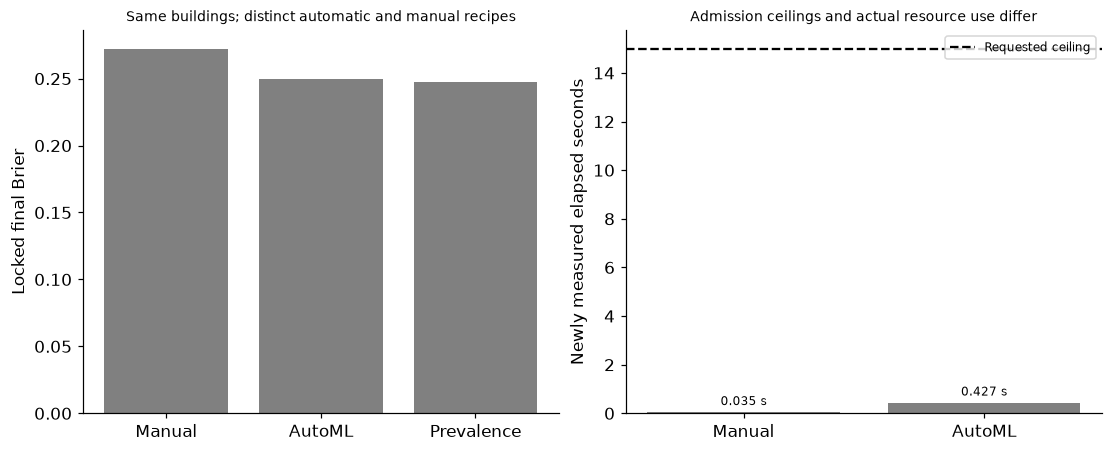

In [2]:
import tempfile,importlib.metadata as metadata
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss,log_loss
from autogluon.tabular import TabularPredictor
from autogluon.features.generators import AutoMLPipelineFeatureGenerator
VERSIONS['autogluon.tabular']=metadata.version('autogluon.tabular');VERSIONS['lightgbm']=metadata.version('lightgbm');RESOURCE_OBSERVATIONS={}
group=np.repeat(np.arange(120),4);b=rng.normal(size=(120,2));load=rng.uniform(-1,1,480);X=pd.DataFrame({'severity':b[group,0],'load':load,'zone':np.where(b[group,1]>0,'coastal','inland')});latent=.9*np.sin(X.severity.to_numpy())+.7*load+.4*(X.zone=='coastal').to_numpy()+rng.normal(scale=.25,size=120)[group];Y=(rng.random(480)<1/(1+np.exp(-latent))).astype(int);X.loc[rng.random(480)<.05,'severity']=np.nan;source=group<72;development=(group>=72)&(group<96);final=group>=96;ceiling=15.;manual_start=time.perf_counter();preprocess=ColumnTransformer([('numeric',make_pipeline(SimpleImputer(),StandardScaler()),['severity','load']),('zone',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['zone'])]).fit(X[source]);SX=preprocess.transform(X[source]);DX=preprocess.transform(X[development]);manual_trials=[];manual_models=[]
for family,value in [('Logistic',.1),('Logistic',1.),('Logistic',10.),('HGB',2),('HGB',3),('HGB',5)]:
    if time.perf_counter()-manual_start>=ceiling:break
    model=LogisticRegression(C=value,max_iter=500) if family=='Logistic' else HistGradientBoostingClassifier(max_depth=int(value),max_iter=80,early_stopping=False,random_state=SEED);model.fit(SX,Y[source]);p=model.predict_proba(DX)[:,1];manual_trials.append({'family':family,'setting':float(value),'development_Brier':float(brier_score_loss(Y[development],p)),'development_log_loss':float(log_loss(Y[development],np.c_[1-p,p],labels=[0,1]))});manual_models.append(model)
manual_seconds=time.perf_counter()-manual_start;assert manual_trials;chosen=int(np.argmin([r['development_log_loss'] for r in manual_trials]));manual_p=manual_models[chosen].predict_proba(preprocess.transform(X[final]))[:,1]
class SourceOnlyGenerator(AutoMLPipelineFeatureGenerator):
    def __init__(self):super().__init__(verbosity=0);self.fit_audit=[]
    def fit_transform(self,X,*args,**kwargs):self.fit_audit.append(X.index.tolist());return super().fit_transform(X,*args,**kwargs)
auto_start=time.perf_counter();fg=SourceOnlyGenerator();fg.fit_transform(X[source]);assert fg.is_fit();train=X[source].assign(target=Y[source]);valid=X[development].assign(target=Y[development]);remaining=max(.1,ceiling-(time.perf_counter()-auto_start))
with tempfile.TemporaryDirectory(prefix='mlbook-automl-') as tmp:
    predictor=TabularPredictor(label='target',problem_type='binary',eval_metric='log_loss',path=tmp,verbosity=0).fit(train,tuning_data=valid,time_limit=remaining,hyperparameters={'GBM':{'num_boost_round':80,'num_threads':1},'RF':{'n_estimators':80},'NN_TORCH':{'num_epochs':25}},feature_generator=fg,num_cpus=1,num_gpus=0,num_bag_folds=0,fit_strategy='sequential',dynamic_stacking=False,calibrate_decision_threshold=False)
    auto_p=predictor.predict_proba(X[final])[1].to_numpy();leader=predictor.leaderboard(silent=True);native_rows=[{'model':str(r.model),'development_negative_log_loss':float(r.score_val)} for r in leader.itertuples()];native_rows.sort(key=lambda r:r['model']);native_best=predictor.model_best
auto_seconds=time.perf_counter()-auto_start;assert fg.fit_audit==[X[source].index.tolist()] and {r['model'] for r in native_rows}=={'LightGBM','RandomForest','NeuralNetTorch','WeightedEnsemble_L2'};assert set(group[source]).isdisjoint(set(group[development])|set(group[final]))
assessments=[]
for name,p in [('Manual selected',manual_p),('Native AutoML',auto_p),('Source prevalence',np.repeat(Y[source].mean(),int(final.sum())))]:assessments.append({'workflow':name,'final_Brier':float(brier_score_loss(Y[final],p)),'final_log_loss':float(log_loss(Y[final],np.c_[1-p,p],labels=[0,1]))})
RESOURCE_OBSERVATIONS.update(manual_seconds=manual_seconds,AutoML_seconds=auto_seconds,seconds_ceiling_each=ceiling,manual_overrun_seconds=max(0.,manual_seconds-ceiling),AutoML_overrun_seconds=max(0.,auto_seconds-ceiling),AutoML_fit_time_request_seconds=remaining)
RESULTS.update(building_roles=[72,24,24],records_per_building=4,manual_trials=manual_trials,manual_selected_trial=chosen,native_models=native_rows,native_selected=native_best,feature_generator_fit_calls=len(fg.fit_audit),feature_generator_fit_rows=fg.fit_audit[0],feature_generator_source_only=True,final_assessments=assessments,final_used_for_selection=False,CPU_count=1,GPU_count=0,budget_ceiling_seconds=15.)
display(pd.DataFrame(assessments));print('Resource observations:',RESOURCE_OBSERVATIONS);fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['final_Brier'] for r in assessments],color='.5');axes[0].set(xticks=range(3),xticklabels=['Manual','AutoML','Prevalence'],ylabel='Locked final Brier',title='Same buildings; distinct automatic and manual recipes');axes[1].bar(range(2),[manual_seconds,auto_seconds],color='.5');axes[1].axhline(ceiling,color='black',linestyle='--',label='Requested ceiling');axes[1].set(xticks=range(2),xticklabels=['Manual','AutoML'],ylabel='Newly measured elapsed seconds',title='Admission ceilings and actual resource use differ');axes[1].legend(fontsize=8,loc='upper right')
for j,value in enumerate([manual_seconds,auto_seconds]):axes[1].text(j,value+.3,f'{value:.3f} s',ha='center',fontsize=8)
plt.show()


<a id="auditable-proposals-and-information-access"></a>
 ## Audit proposals before they consume a protected role or an unbounded budget
 Model-selection agents can propose code and revise workflows; the book discusses primary research separately from this executed native AutoML run. The small contract below is an actual deterministic proposal validator, not a claimed executed language-model agent. It checks an allowed model family, source-only fitting role and a positive update allocation within a remaining budget. Three supplied proposals illustrate a rejected request for final-label fitting, a rejected oversize allocation and one admitted source fit request. They are validated records, not three additional model fits. Preserve the proposal log, admitted operations, data-role reads, failure records and selection rule when evaluating an actual agent. Fluent generated code does not establish an independent final assessment.


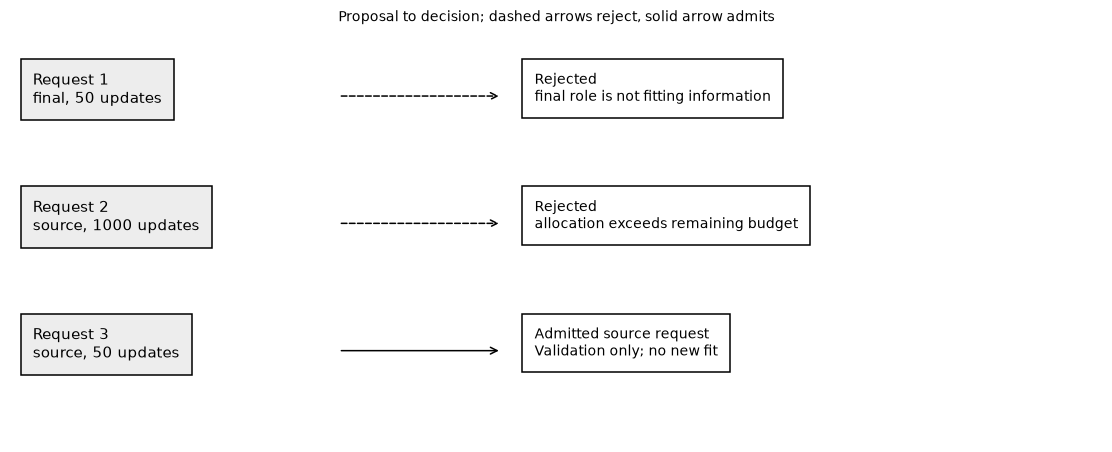

In [3]:
proposals=[{'family':'HGB','fit_role':'final','updates':50},{'family':'HGB','fit_role':'source','updates':1000},{'family':'HGB','fit_role':'source','updates':50}];remaining_updates=100;audit=[]
for proposal in proposals:
    if proposal['fit_role']!='source':reason='Rejected: final role is not fitting information'
    elif proposal['family'] not in ['HGB','Logistic','Neural']:reason='Rejected: undeclared family'
    elif not isinstance(proposal['updates'],int) or not 0<proposal['updates']<=remaining_updates:reason='Rejected: allocation exceeds remaining budget'
    else:reason='Admitted source request; not executed by this validator';remaining_updates-=proposal['updates']
    audit.append({**proposal,'decision':reason,'remaining_updates':remaining_updates})
assert [r['decision'].startswith('Admitted') for r in audit]==[False,False,True] and remaining_updates==50
RESULTS.update(proposal_contract_audit=audit,language_model_agent_executed=False,validator_requests_executed_as_model_fits=0)
fig,ax=plt.subplots(figsize=(10,4));ax.axis('off');ax.set(xlim=(0,1),ylim=(0,1))
for j,row in enumerate(audit):
    yy=.9-j*.31;request=f'Request {j+1}\n{row["fit_role"]}, {row["updates"]} updates';decision=row['decision'].replace('Rejected: ','Rejected\n').replace('Admitted source request; not executed by this validator','Admitted source request\nValidation only; no new fit');ax.text(.02,yy,request,va='top',fontsize=10,bbox={'facecolor':'.93','edgecolor':'black','pad':8});ax.text(.48,yy,decision,va='top',fontsize=9,bbox={'facecolor':'white','edgecolor':'black','pad':8});ax.annotate('',xy=(.45,yy-.06),xytext=(.30,yy-.06),arrowprops={'arrowstyle':'->','linestyle':'--' if j<2 else '-','color':'black'})
ax.set_title('Proposal to decision; dashed arrows reject, solid arrow admits');plt.show()


In [4]:
summary={'example_id':'code_186','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual native AutoGluon LightGBM random forest neural and weighted ensemble fitting', 'source-prefitted native feature generator with fit-call audit', 'same grouped data roles and fifteen-second ceilings for manual and AutoML', 'freshly measured resource observations outside deterministic scientific results', 'explicit proposal validator distinguished from an executed language-model agent'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
summary['resource_observations']=RESOURCE_OBSERVATIONS
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual native AutoGluon LightGBM random forest neural and weighted ensemble fitting", "source-prefitted native feature generator with fit-call audit", "same grouped data roles and fifteen-second ceilings for manual and AutoML", "freshly measured resource observations outside deterministic scientific results", "explicit proposal validator distinguished from an executed language-model agent"], "elapsed_seconds": 1.14, "example_id": "code_186", "hardware": "Darwin arm64 CPU", "resource_observations": {"AutoML_fit_time_request_seconds": 14.995117291982751, "AutoML_overrun_seconds": 0.0, "AutoML_seconds": 0.42719433302409016, "manual_overrun_seconds": 0.0, "manual_seconds": 0.03477816600934602, "seconds_ceiling_each": 15.0}, "results": {"CPU_count": 1, "GPU_count": 0, "budget_ceiling_seconds": 15.0, "building_roles": [72, 24, 24], "feature_generator_fit_calls": 1, "feature_generator_fit_rows": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 